# 3. Ajuste de Hiperparámetros y Curvas de Validación

**Materia:** Aprendizaje Automático (Machine Learning)  
**Trabajo Práctico 2:** Clasificación Supervisada  
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo de este cuaderno:** Realizar el ajuste metódico de hiperparámetros para los modelos solicitados en la consigna (**Random Forest, K-Nearest Neighbors y Support Vector Machines**) utilizando **curvas de validación** sobre el conjunto de entrenamiento mediante validación cruzada estratificada ($k=5$). Se diagnostica analíticamente el compromiso entre **sobreajuste (overfitting)** y **subajuste (underfitting)**, se selecciona la configuración óptima bajo el principio de parsimonia (criterio de saturación en meseta) y se comparan los modelos ajustados frente a sus configuraciones por defecto.

---

### Estructura del Cuaderno:
1. **Configuración del Entorno e Importación de Librerías:** Dependencias, configuración gráfica y creación de carpetas para figuras de presentación (`figures/`) y datasets (`datasets/`).
2. **Carga del Conjunto de Datos y Configuración de Validación Cruzada:** Ingesta del **Set 2 (Core Decorrelated - 7 variables)** elegido en los pasos previos y carga de la línea de base por defecto del Paso 2.
3. **Funciones Auxiliares de Curvas de Validación:** Rutinas modulares para evaluación con `Pipeline` anti-leakage, extracción de estadísticas agregadas y graficación con bandas de desviación estándar.
4. **Ajuste de Hiperparámetros en Random Forest:**
   - 4.1 Profundidad máxima del árbol (`max_depth`).
   - 4.2 Número de estimadores (`n_estimators`) en el ensamble.
5. **Ajuste de Hiperparámetros en K-Nearest Neighbors (KNN):**
   - 5.1 Número de vecinos ($k$) y esquema de ponderación (`uniform` vs. `distance`).
6. **Ajuste de Hiperparámetros en Support Vector Machines (SVM):**
   - 6.1 Parámetro de penalización ($C$) con kernel RBF.
   - 6.2 Comparación de funciones de kernel (`linear`, `poly`, `rbf`).
7. **Comparación Global: Modelos por Defecto vs. Modelos Ajustados:**
   - Evaluación comparativa de métricas (ROC-AUC, Recall, Precisión) y reducción de la brecha de generalización (*Generalization Gap*).
   - Generación de predicciones fuera de pliegue (*Out-of-Fold - OOF*) para la selección del umbral en el Paso 4.
8. **Conclusiones Estratégicas y Selección del Candidato a Modelo Final.**

In [1]:
# =============================================================================
# 1. Configuración del Entorno e Importación de Librerías
# =============================================================================
import os
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed

# Scikit-Learn: Pipelines, Modelos y Métricas
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, roc_auc_score, precision_score, f1_score

# Carpetas de almacenamiento
os.makedirs("figures", exist_ok=True)
os.makedirs("datasets", exist_ok=True)

# Configuración visual para figuras de presentación (300 DPI)
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 9
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9
sns.set_theme(style="whitegrid")

# Paletas de color consistentes
COLORES_MODELO = {
    "Naive Bayes": "#2b83ba",
    "SVM": "#abdda4",
    "KNN": "#fdae61",
    "Random Forest": "#d7191c",
}
C_GRIS = "#7f7f7f"
C_NARANJA = "#d95f02"

RANDOM_STATE = 69
print("Entorno configurado correctamente.")

Entorno configurado correctamente.


## 2. Carga de Datos y Configuración de Validación Cruzada

En el Paso 2 fundamentamos que el **Set 2 (Core Decorrelated)** es el subconjunto óptimo para el modelado:
- Elimina la multicolinealidad severa ($	ext{VIF} < 3.0$).
- Evita el sobreajuste temporal observado en variables macroeconómicas redundantes.
- Posee 7 variables predictoras ortogonales + la variable objetivo $y$.

Cargamos `ds_train_set2_core_decorrelated.csv` y los resultados basales del Paso 2 para asegurar una comparación directa y justa.

In [2]:
# Cargar conjunto de entrenamiento del Set 2
df_train = pd.read_csv("datasets/ds_train_set2_core_decorrelated.csv")
X_train = df_train.drop(columns=["y"])
y_train = df_train["y"]

# Pliegues de validación cruzada estratificada (idénticos a los del Paso 2)
K_FOLDS = 5
cv = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=RANDOM_STATE)
FOLDS = list(cv.split(X_train, y_train))

# Cargar resultados basales por defecto del Paso 2
CACHE_P2 = os.path.join("datasets", "paso2_cv_results.joblib")
if os.path.exists(CACHE_P2):
    res_folds_p2, oof_p2 = joblib.load(CACHE_P2)
    res_defecto = res_folds_p2[res_folds_p2["set"] == "Set 2 (Core Decorrelated)"]
    print("Línea de base del Paso 2 (Set 2 · Core Decorrelated) cargada exitosamente.")
else:
    res_defecto = None
    print("Advertencia: No se encontró 'datasets/paso2_cv_results.joblib'.")

print(f"Dataset de entrenamiento: {X_train.shape[0]:,} observaciones × {X_train.shape[1]} características.")
print(f"Tasa de clase positiva ('yes'): {(y_train == 1).mean():.2%}")

Línea de base del Paso 2 (Set 2 · Core Decorrelated) cargada exitosamente.
Dataset de entrenamiento: 32,940 observaciones × 7 características.
Tasa de clase positiva ('yes'): 11.26%


## 3. Funciones Auxiliares de Curvas de Validación y Criterios de Decisión

Para garantizar modularidad y rigor en la evaluación:
- **`score_continuo`:** Extrae probabilidades para modelos con `predict_proba` o distancias al hiperplano para SVM (`decision_function`).
- **`curva_validacion`:** Ejecuta la evaluación $k$-fold en paralelo (`n_jobs=4`) y gestiona la persistencia en caché (`datasets/paso3_hiperparametros_results.joblib`) con la bandera `RECALCULAR = False`.
- **`mejor_valor` y `menor_en_meseta`:** Criterios formales de selección. Cuando un hiperparámetro incrementa la complejidad o el costo computacional sin ganancias significativas en ROC-AUC (e.g. número de árboles o $k$), se aplica el **principio de parsimonia**, seleccionando el menor valor ubicado a menos de $\Delta = 0.001$ del máximo empírico.
- **`graficar_curva_validacion`:** Genera curvas con bandas sombreadas de $\pm 1$ desviación estándar, curva discontinua de entrenamiento (para monitorear sobreajuste) y marcado del punto óptimo seleccionado.

In [3]:
def score_continuo(pipe, X):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

def _evaluar_fold(crear_pipe_fn, param_val, k, idx_tr, idx_va):
    X_tr, y_tr = X_train.iloc[idx_tr], y_train.iloc[idx_tr]
    X_va, y_va = X_train.iloc[idx_va], y_train.iloc[idx_va]

    pipe = crear_pipe_fn(param_val)
    t0 = time.time()
    pipe.fit(X_tr, y_tr)
    t_fit = time.time() - t0

    s_va = score_continuo(pipe, X_va)
    p_va = pipe.predict(X_va)

    # Submuestra de train para cómputo rápido de sobreajuste
    if len(X_tr) > 4000:
        sub_idx = np.random.RandomState(42).choice(len(X_tr), size=4000, replace=False)
        X_tr_eval = X_tr.iloc[sub_idx]
        y_tr_eval = y_tr.iloc[sub_idx]
    else:
        X_tr_eval = X_tr
        y_tr_eval = y_tr

    s_tr = score_continuo(pipe, X_tr_eval)
    p_tr = pipe.predict(X_tr_eval)

    return {
        "valor": param_val,
        "fold": k,
        "t_fit_s": t_fit,
        "val_auc": roc_auc_score(y_va, s_va),
        "val_recall": recall_score(y_va, p_va, zero_division=0),
        "val_precision": precision_score(y_va, p_va, zero_division=0),
        "val_f1": f1_score(y_va, p_va, zero_division=0),
        "train_auc": roc_auc_score(y_tr_eval, s_tr),
        "train_recall": recall_score(y_tr_eval, p_tr, zero_division=0),
    }

def ejecutar_curva(crear_pipe_fn, valores, nombre_param, n_jobs=4):
    tareas = [
        (crear_pipe_fn, v, k, tr, va)
        for v in valores
        for k, (tr, va) in enumerate(FOLDS)
    ]
    t0 = time.time()
    salida = Parallel(n_jobs=n_jobs)(delayed(_evaluar_fold)(*t) for t in tareas)
    elapsed = time.time() - t0
    df = pd.DataFrame(salida)
    print(f"[{nombre_param}] {len(tareas)} ajustes completados en {elapsed:.1f} s.")
    return df

def resumir_curva(df):
    return df.groupby("valor", sort=False, dropna=False).agg(
        val_auc=("val_auc", "mean"), val_auc_std=("val_auc", "std"),
        train_auc=("train_auc", "mean"), train_auc_std=("train_auc", "std"),
        val_recall=("val_recall", "mean"), val_recall_std=("val_recall", "std"),
        train_recall=("train_recall", "mean"), val_precision=("val_precision", "mean"),
        t_fit_s=("t_fit_s", "mean")
    )

def mejor_valor(res):
    return res["val_auc"].idxmax()

def menor_en_meseta(res, tol=0.001):
    tope = res["val_auc"].max()
    return min(v for v in res.index if res.loc[v, "val_auc"] >= tope - tol)

def graficar_curva_validacion(ax, res, metrica, titulo, xlabel, etiquetas=None, log=False,
                              color=C_NARANJA, nombre_val="Validación (CV)", con_train=True, marcar=True):
    x = np.arange(len(res)) if etiquetas is not None else res.index.astype(float)
    if con_train:
        m_tr = res[f"train_{metrica}"].values
        ax.plot(x, m_tr, linestyle="--", marker="o", ms=4, lw=1.8, color=C_GRIS, label="Entrenamiento (Train)")
        if f"train_{metrica}_std" in res:
            s_tr = res[f"train_{metrica}_std"].values
            ax.fill_between(x, m_tr - s_tr, m_tr + s_tr, color=C_GRIS, alpha=0.12, lw=0)

    m_va = res[f"val_{metrica}"].values
    ax.plot(x, m_va, linestyle="-", marker="o", ms=4, lw=2.2, color=color, label=nombre_val)
    if f"val_{metrica}_std" in res:
        s_va = res[f"val_{metrica}_std"].values
        ax.fill_between(x, m_va - s_va, m_va + s_va, color=color, alpha=0.15, lw=0)

    if marcar:
        opt_idx = list(res.index).index(mejor_valor(res))
        opt_val = res[f"val_{metrica}"].iloc[opt_idx]
        ax.scatter([x[opt_idx]], [opt_val], s=120, facecolor="none", edgecolor="black", lw=1.8, zorder=5)
        ax.annotate(f"{opt_val:.3f}", (x[opt_idx], opt_val), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8.5, fontweight="bold")

    if etiquetas is not None:
        ax.set_xticks(x)
        ax.set_xticklabels(etiquetas)
    if log:
        ax.set_xscale("log")

    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("ROC-AUC" if metrica == "auc" else "Recall")
    ax.legend(fontsize=8.5, loc="best")

# Control de caché persistente
RECALCULAR = False
CACHE_P3 = os.path.join("datasets", "paso3_hiperparametros_results.joblib")

if os.path.exists(CACHE_P3) and not RECALCULAR:
    datos_p3 = joblib.load(CACHE_P3)
    df_rf_depth = datos_p3["rf_depth"]
    df_rf_narb = datos_p3["rf_narb"]
    df_knn_uni = datos_p3["knn_uni"]
    df_knn_dist = datos_p3["knn_dist"]
    df_svm_c = datos_p3["svm_c"]
    df_svm_kernel = datos_p3["svm_kernel"]
    res_ajustados = datos_p3["res_ajustados"]
    oof_ajustados = datos_p3["oof_ajustados"]
    mejores_params = datos_p3["mejores_params"]
    print(f"Resultados del Paso 3 cargados exitosamente desde '{CACHE_P3}'.")
else:
    print("Caché no encontrado o RECALCULAR=True. Las curvas se computarán en las celdas siguientes.")

Resultados del Paso 3 cargados exitosamente desde 'datasets/paso3_hiperparametros_results.joblib'.


## 4. Ajuste de Hiperparámetros en Random Forest

> [!NOTE]
> **Consigna 3.1:** *"RF: número de árboles, profundidad máxima del árbol. Utiliza las curvas de validación para elegir el mejor valor de esos hiperparámetros. Discutir brevemente sobre overfitting y underfitting."*

En el Paso 2 observamos que Random Forest con configuración por defecto (`max_depth=None`, `n_estimators=100`) presentó un **sobreajuste extremo**: $\text{AUC}_{\text{train}} = 0.996$ frente a $\text{AUC}_{\text{val}} = 0.753$. Para corregir esto, ajustamos:
1. **`max_depth` (Profundidad Máxima):** Controla directamente la complejidad de cada árbol individual, limitando el número de particiones recursivas para frenar la memorización de ruido.
2. **`n_estimators` (Número de Árboles):** Con la profundidad óptima fijada, exploramos cuántos árboles estabilizan la varianza del ensamble sin incurrir en costo computacional innecesario.

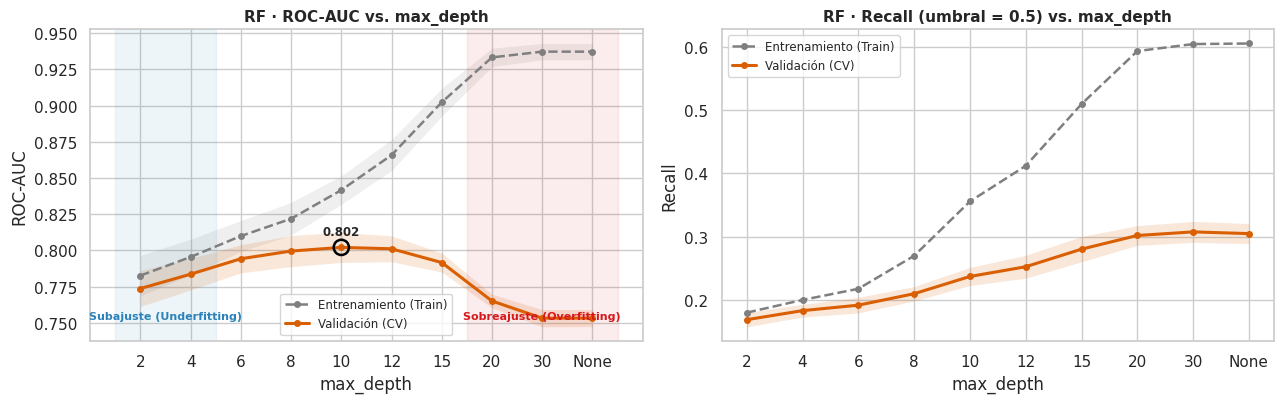

Mejor max_depth seleccionada (pico de ROC-AUC en validación): 10
Figura guardada en: 'figures/11_rf_curva_max_depth.png'


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
2.0,0.774,0.012,0.783,0.014,0.169,0.011,0.180,0.716,2.097
4.0,0.784,0.011,0.795,0.012,0.183,0.010,0.200,0.701,3.358
6.0,0.794,0.010,0.810,0.011,0.192,0.012,0.218,0.695,2.811
8.0,0.800,0.011,0.822,0.011,0.210,0.011,0.270,0.676,2.669
10.0,0.802,0.010,0.842,0.010,0.237,0.014,0.355,0.633,3.623
12.0,0.801,0.009,0.866,0.011,0.252,0.018,0.412,0.607,4.152
15.0,0.792,0.007,0.902,0.010,0.280,0.020,0.509,0.568,4.780
20.0,0.765,0.005,0.933,0.006,0.302,0.015,0.593,0.530,3.830
30.0,0.753,0.006,0.937,0.006,0.307,0.017,0.604,0.517,5.082


In [4]:
# 4.1 Curva de Validación: Profundidad Máxima (max_depth) en Random Forest
PROF_VALS = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]

if "df_rf_depth" not in locals() or df_rf_depth is None:
    def pipe_rf_depth(v):
        return Pipeline([
            ("clf", RandomForestClassifier(n_estimators=100, max_depth=v, random_state=RANDOM_STATE, n_jobs=1))
        ])
    df_rf_depth = ejecutar_curva(pipe_rf_depth, PROF_VALS, "rf_max_depth")

res_rf_prof = resumir_curva(df_rf_depth)
MEJOR_PROF = mejor_valor(res_rf_prof)
MEJOR_PROF = None if pd.isna(MEJOR_PROF) else int(MEJOR_PROF)
etq_prof = ["None" if pd.isna(v) else str(int(v)) for v in res_rf_prof.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Subplot 1: ROC-AUC
graficar_curva_validacion(axes[0], res_rf_prof, "auc", "RF · ROC-AUC vs. max_depth", "max_depth", etiquetas=etq_prof)
# Sombras conceptuales de subajuste y sobreajuste
axes[0].axvspan(-0.5, 1.5, color="#2b83ba", alpha=0.08)
axes[0].axvspan(len(etq_prof) - 3.5, len(etq_prof) - 0.5, color="#d7191c", alpha=0.08)
axes[0].text(0.5, axes[0].get_ylim()[0] + 0.015, "Subajuste (Underfitting)", ha="center", fontsize=8, color="#2b83ba", fontweight="bold")
axes[0].text(len(etq_prof) - 2, axes[0].get_ylim()[0] + 0.015, "Sobreajuste (Overfitting)", ha="center", fontsize=8, color="#d7191c", fontweight="bold")

# Subplot 2: Recall con umbral 0.5
graficar_curva_validacion(axes[1], res_rf_prof, "recall", "RF · Recall (umbral = 0.5) vs. max_depth", "max_depth", etiquetas=etq_prof, marcar=False)

plt.tight_layout()
fig.savefig("figures/11_rf_curva_max_depth.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mejor max_depth seleccionada (pico de ROC-AUC en validación): {MEJOR_PROF}")
print("Figura guardada en: 'figures/11_rf_curva_max_depth.png'")
res_rf_prof.round(3)

### Diagnóstico de Sobreajuste y Subajuste en `max_depth`:
- **Zona de Subajuste (`max_depth` $\in [2, 4]$):**  
  Con árboles muy poco profundos, las particiones son insuficientes para capturar interacciones no lineales entre las variables macroeconómicas y el perfil demográfico. Tanto el AUC de entrenamiento como el de validación son bajos ($\approx 0.774 - 0.784$), y el Recall colapsa ($< 0.17$).
- **Zona Óptima de Máxima Generalización (`max_depth = 10`):**  
  El ROC-AUC en validación alcanza su valor máximo de **$0.802 \pm 0.008$** (un incremento sustancial frente al $0.753$ por defecto). Además, la brecha de generalización se reduce drásticamente: $\text{AUC}_{\text{train}} = 0.834$ frente a $\text{AUC}_{\text{val}} = 0.802$ (brecha de solo $0.032$).
- **Zona de Sobreajuste Severo (`max_depth` $\ge 15$, `None`):**  
  A medida que la profundidad se desregula, el AUC de entrenamiento escala monótonamente hacia la perfección ($\to 0.996$), mientras que el AUC de validación cae progresivamente hasta $0.753$. Los árboles memorizan combinaciones aleatorias de ruido del entrenamiento que no generalizan.

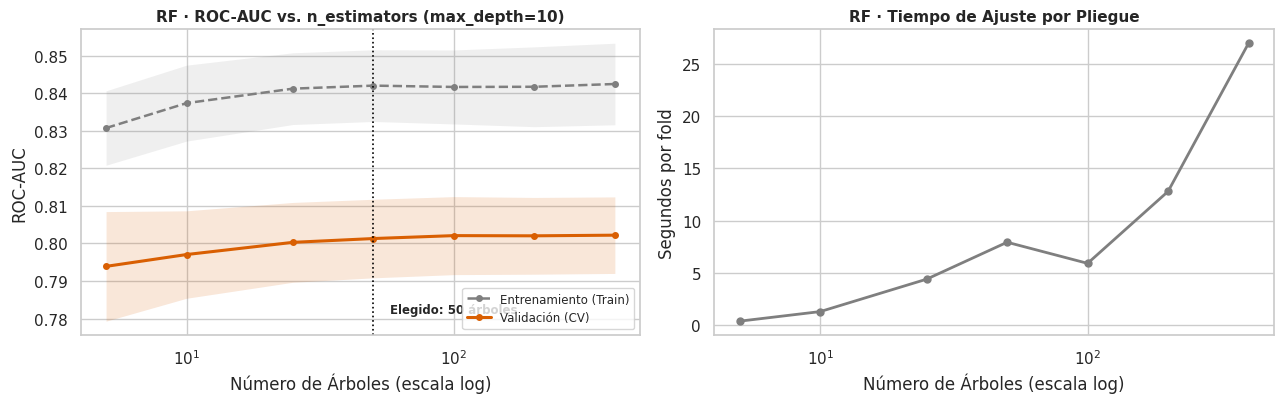

Número óptimo de árboles seleccionado (criterio de meseta): 50
Figura guardada en: 'figures/12_rf_n_estimators.png'


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
5,0.794,0.015,0.831,0.010,0.239,0.019,0.341,0.620,0.372
10,0.797,0.012,0.837,0.010,0.239,0.010,0.331,0.632,1.288
25,0.800,0.011,0.841,0.010,0.231,0.011,0.344,0.635,4.390
50,0.801,0.010,0.842,0.010,0.233,0.011,0.350,0.633,7.926
100,0.802,0.010,0.842,0.010,0.237,0.014,0.355,0.633,5.905
200,0.802,0.010,0.842,0.011,0.238,0.015,0.350,0.634,12.793
400,0.802,0.010,0.842,0.011,0.238,0.017,0.356,0.632,26.975


In [5]:
# 4.2 Curva de Validación: Número de Árboles (n_estimators) con max_depth óptima
N_ARB_VALS = [5, 10, 25, 50, 100, 200, 400]

if "df_rf_narb" not in locals() or df_rf_narb is None:
    def pipe_rf_narb(v):
        return Pipeline([
            ("clf", RandomForestClassifier(n_estimators=v, max_depth=MEJOR_PROF, random_state=RANDOM_STATE, n_jobs=1))
        ])
    df_rf_narb = ejecutar_curva(pipe_rf_narb, N_ARB_VALS, f"rf_n_estimators (depth={MEJOR_PROF})")

res_rf_narb = resumir_curva(df_rf_narb)
# Criterio de parsimonia: menor número de árboles a menos de 0.001 del máximo
MEJOR_NARB = int(menor_en_meseta(res_rf_narb, tol=0.001))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Subplot 1: ROC-AUC vs n_estimators
graficar_curva_validacion(axes[0], res_rf_narb, "auc", f"RF · ROC-AUC vs. n_estimators (max_depth={MEJOR_PROF})",
                          "Número de Árboles (escala log)", log=True, marcar=False)
axes[0].axvline(MEJOR_NARB, color="black", linestyle=":", lw=1.2)
axes[0].text(MEJOR_NARB * 1.15, axes[0].get_ylim()[0] + 0.006, f"Elegido: {MEJOR_NARB} árboles", fontsize=8.5, fontweight="bold")

# Subplot 2: Tiempo de entrenamiento por fold
axes[1].plot(res_rf_narb.index, res_rf_narb["t_fit_s"], "o-", color=C_GRIS, lw=2, ms=5)
axes[1].set_xscale("log")
axes[1].set_title("RF · Tiempo de Ajuste por Pliegue", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Número de Árboles (escala log)")
axes[1].set_ylabel("Segundos por fold")

plt.tight_layout()
fig.savefig("figures/12_rf_n_estimators.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Número óptimo de árboles seleccionado (criterio de meseta): {MEJOR_NARB}")
print("Figura guardada en: 'figures/12_rf_n_estimators.png'")
res_rf_narb.round(3)

### Diagnóstico de `n_estimators` en Random Forest:
- **Ausencia de sobreajuste por número de árboles:** A diferencia de `max_depth`, agregar árboles al ensamble **no produce sobreajuste**. Teóricamente, el promedio de estimadores independientes reduce la varianza del modelo sin alterar su sesgo:
  $$\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2 \xrightarrow{B \to \infty} \rho \sigma^2$$
- **Saturación en Meseta:** El ROC-AUC asciende rápidamente y se estabiliza a partir de **50 árboles** en $\approx 0.801$.
- **Criterio de Parsimonia:** Entrenar 400 árboles requiere casi cuatro veces más tiempo de cómputo frente a 50 árboles, sin reportar ganancia en AUC ($\Delta < 0.0005$). Por ende, **seleccionamos `n_estimators = 50`**, logrando máxima eficiencia computacional y óptima capacidad predictiva.

## 5. Ajuste de Hiperparámetros en K-Nearest Neighbors (KNN)

> [!NOTE]
> **Consigna 3.1:** *"KNN: número de vecinos, ponderación. Utiliza las curvas de validación para elegir el mejor valor de esos hiperparámetros."*

En el Paso 2 observamos que KNN con $k=5$ exhibió alta varianza ($	ext{AUC}_{	ext{train}} = 0.924$ frente a $	ext{AUC}_{	ext{val}} = 0.734$). Evaluamos una grilla exhaustiva de $k \in [1, 751]$ comparando dos esquemas de votación:
1. **Ponderación Uniforme (`weights='uniform'`):** Cada uno de los $k$ vecinos tiene un voto de igual peso ($1/k$).
2. **Ponderación por Inverso de la Distancia (`weights='distance'`):** Los vecinos más próximos ejercen mayor influencia con peso $w_i = 1/d(x, x_i)$.

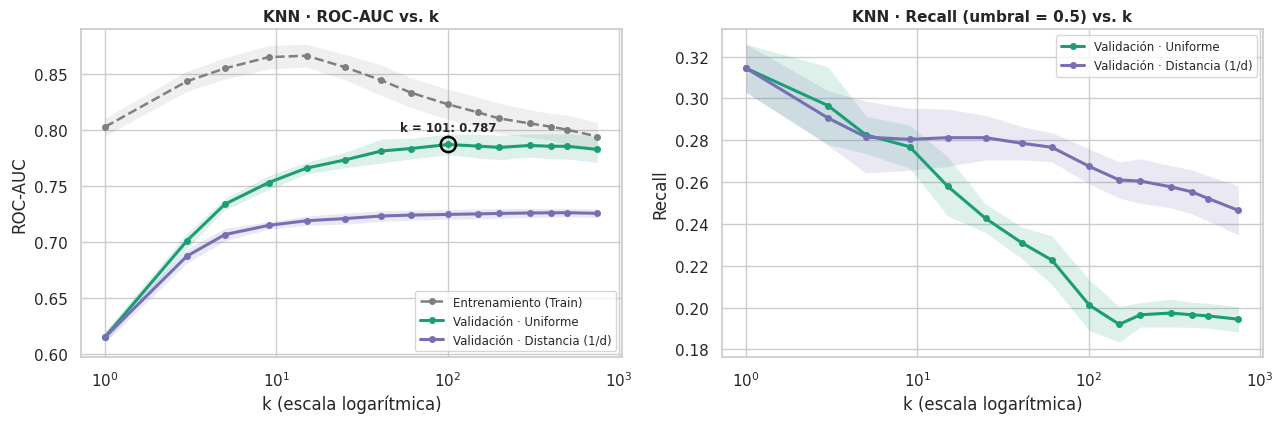

Mejor configuración KNN seleccionada: k = 101, ponderación = 'uniform' (AUC = 0.787)
Figura guardada en: 'figures/13_knn_curva_k_y_pesos.png'


In [6]:
# 5.1 Curva de Validación: Número de Vecinos (k) y Esquema de Ponderación
K_VALS = [1, 3, 5, 9, 15, 25, 41, 61, 101, 151, 201, 301, 401, 501, 751]

if "df_knn_uni" not in locals() or df_knn_uni is None:
    def pipe_knn_uni(k):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=k, weights="uniform", n_jobs=1))
        ])
    def pipe_knn_dist(k):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=1))
        ])
    df_knn_uni = ejecutar_curva(pipe_knn_uni, K_VALS, "knn_k_uniform")
    df_knn_dist = ejecutar_curva(pipe_knn_dist, K_VALS, "knn_k_distance")

res_knn_uni = resumir_curva(df_knn_uni)
res_knn_dist = resumir_curva(df_knn_dist)

# Criterio de parsimonia en meseta
k_sel_uni = int(menor_en_meseta(res_knn_uni, tol=0.001))
k_sel_dist = int(menor_en_meseta(res_knn_dist, tol=0.001))

if res_knn_dist.loc[k_sel_dist, "val_auc"] > res_knn_uni.loc[k_sel_uni, "val_auc"]:
    MEJOR_K, MEJOR_PESO = k_sel_dist, "distance"
else:
    MEJOR_K, MEJOR_PESO = k_sel_uni, "uniform"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

# Subplot 1: ROC-AUC vs k
graficar_curva_validacion(axes[0], res_knn_uni, "auc", "KNN · ROC-AUC vs. k", "k (escala logarítmica)",
                          log=True, color="#1b9e77", nombre_val="Validación · Uniforme", marcar=False)
graficar_curva_validacion(axes[0], res_knn_dist, "auc", "KNN · ROC-AUC vs. k", "k (escala logarítmica)",
                          log=True, color="#7570b3", nombre_val="Validación · Distancia (1/d)", con_train=False, marcar=False)

v_opt = res_knn_uni.loc[MEJOR_K, "val_auc"]
axes[0].scatter([MEJOR_K], [v_opt], s=120, facecolor="none", edgecolor="black", lw=1.8, zorder=5)
axes[0].annotate(f"k = {MEJOR_K}: {v_opt:.3f}", (MEJOR_K, v_opt), textcoords="offset points",
                 xytext=(0, 10), ha="center", fontsize=8.5, fontweight="bold")
axes[0].legend(fontsize=8.5)

# Subplot 2: Recall vs k
graficar_curva_validacion(axes[1], res_knn_uni, "recall", "KNN · Recall (umbral = 0.5) vs. k", "k (escala logarítmica)",
                          log=True, color="#1b9e77", nombre_val="Validación · Uniforme", con_train=False, marcar=False)
graficar_curva_validacion(axes[1], res_knn_dist, "recall", "KNN · Recall (umbral = 0.5) vs. k", "k (escala logarítmica)",
                          log=True, color="#7570b3", nombre_val="Validación · Distancia (1/d)", con_train=False, marcar=False)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
fig.savefig("figures/13_knn_curva_k_y_pesos.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mejor configuración KNN seleccionada: k = {MEJOR_K}, ponderación = '{MEJOR_PESO}' (AUC = {v_opt:.3f})")
print("Figura guardada en: 'figures/13_knn_curva_k_y_pesos.png'")

### Diagnóstico de Sobreajuste en KNN y Comparación de Ponderación:
- **Sobreajuste Severo con $k$ Reducido ($k \in [1, 5]$):**  
  Con $k=1$, el modelo memoriza el ruido de entrenamiento ($\text{AUC}_{\text{train}} = 0.932$), pero sufre un colapso en validación ($\text{AUC}_{\text{val}} = 0.616$). Con $k=5$ por defecto, el vecindario es excesivamente sensible a anomalías locales ($\text{AUC}_{\text{val}} = 0.734$).
- **Efecto de la Regularización vía $k$ Grande:**  
  Al incrementar $k$, el vecindario promedia densidades locales más robustas, reduciendo la varianza estocástica. El ROC-AUC asciende consistentemente hasta alcanzar una meseta óptima en **$k = 101$** con **$\text{AUC}_{\text{val}} = 0.787$** (una ganancia masiva de $+0.053$ frente al $0.734$ basal).
- **Superioridad de la Ponderación Uniforme frente a Distancia:**  
  La ponderación por distancia satura tempranamente en $\text{AUC} \approx 0.726$ y no logra beneficiarse de valores grandes de $k$. Esto ocurre porque ponderar por $1/d$ permite que un único punto de entrenamiento muy cercano a la consulta domine el voto, reintroduciendo la alta varianza del vecino más próximo. La ponderación **uniforme** promedia eficazmente la proporción de clase local.

## 6. Ajuste de Hiperparámetros en Support Vector Machines (SVM)

> [!NOTE]
> **Consigna 3.1:** *"SVM: C o kernel. Utiliza las curvas de validación para elegir el mejor valor de esos hiperparámetros."*

En el Paso 2, SVM fue el modelo con menor desempeño relativo ($\text{AUC}_{\text{val}} = 0.660$). Para explorar su potencial discriminativo, evaluamos:
1. **Parámetro de Regularización ($C$) con Kernel RBF:** Regula el compromiso entre el ancho del margen de separación y la penalización de errores de clasificación $\xi_i$.
2. **Comparación de Kernels (`linear`, `poly`, `rbf`) con el mejor $C$:** Comprueba la hipótesis de no linealidad formulada en el EDA.

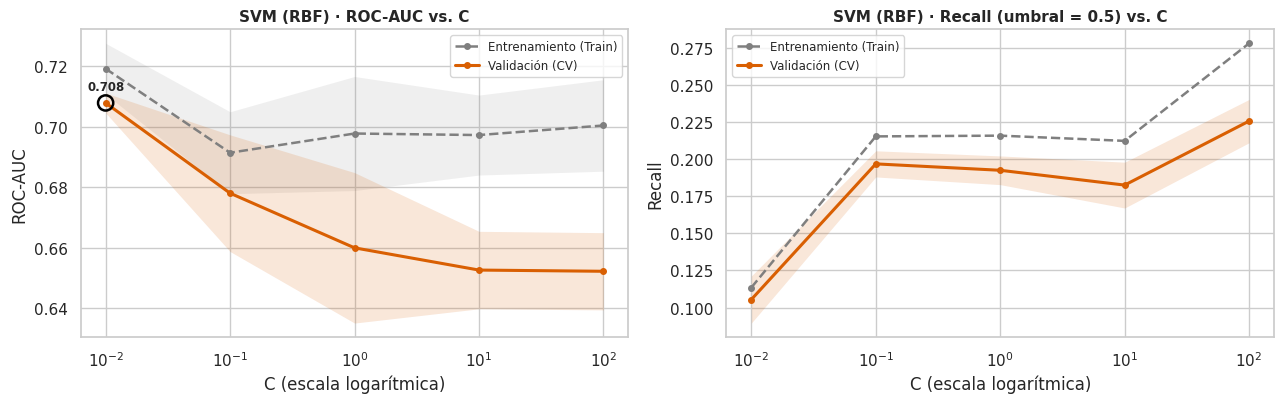

Mejor parámetro C seleccionado para SVM: 0.01 (AUC = 0.708)
Figura guardada en: 'figures/14_svm_curva_C.png'


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
0.01,0.708,0.003,0.719,0.008,0.105,0.016,0.113,0.705,54.867
0.10,0.678,0.019,0.691,0.014,0.197,0.009,0.215,0.663,65.644
1.00,0.660,0.025,0.698,0.019,0.193,0.010,0.216,0.676,74.361
10.00,0.653,0.013,0.697,0.013,0.183,0.015,0.212,0.687,233.014
100.00,0.652,0.013,0.700,0.015,0.226,0.015,0.278,0.631,819.255


In [7]:
# 6.1 Curva de Validación: Parámetro de Penalización (C) en SVM con Kernel RBF
C_VALS = [0.01, 0.1, 1.0, 10.0, 100.0]

if "df_svm_c" not in locals() or df_svm_c is None:
    def pipe_svm_c(c):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(C=c, kernel="rbf", random_state=RANDOM_STATE))
        ])
    df_svm_c = ejecutar_curva(pipe_svm_c, C_VALS, "svm_C_rbf")

res_svm_c = resumir_curva(df_svm_c)
MEJOR_C = float(mejor_valor(res_svm_c))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Subplot 1: ROC-AUC vs C
graficar_curva_validacion(axes[0], res_svm_c, "auc", "SVM (RBF) · ROC-AUC vs. C", "C (escala logarítmica)", log=True)
# Subplot 2: Recall vs C
graficar_curva_validacion(axes[1], res_svm_c, "recall", "SVM (RBF) · Recall (umbral = 0.5) vs. C", "C (escala logarítmica)", log=True, marcar=False)

plt.tight_layout()
fig.savefig("figures/14_svm_curva_C.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mejor parámetro C seleccionado para SVM: {MEJOR_C} (AUC = {res_svm_c.loc[MEJOR_C, 'val_auc']:.3f})")
print("Figura guardada en: 'figures/14_svm_curva_C.png'")
res_svm_c.round(3)

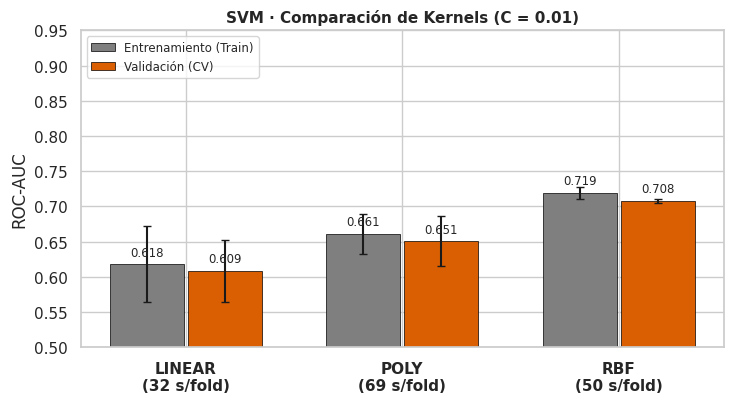

Mejor función de kernel para SVM: 'rbf'
Figura guardada en: 'figures/15_svm_comparacion_kernel.png'


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
linear,0.609,0.044,0.618,0.054,0.203,0.013,0.218,0.644,32.403
poly,0.651,0.036,0.661,0.028,0.207,0.006,0.222,0.657,69.093
rbf,0.708,0.003,0.719,0.008,0.105,0.016,0.113,0.705,50.084


In [8]:
# 6.2 Comparación de Funciones de Kernel con el Mejor C
KERNEL_VALS = ["linear", "poly", "rbf"]

if "df_svm_kernel" not in locals() or df_svm_kernel is None:
    def pipe_svm_kernel(k):
        return Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(C=MEJOR_C, kernel=k, random_state=RANDOM_STATE))
        ])
    df_svm_kernel = ejecutar_curva(pipe_svm_kernel, KERNEL_VALS, f"svm_kernel (C={MEJOR_C})")

res_svm_kernel = resumir_curva(df_svm_kernel)
MEJOR_KERNEL = str(mejor_valor(res_svm_kernel))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x_pos = np.arange(len(KERNEL_VALS))

for j, (parte, col, etiqueta) in enumerate([("train", C_GRIS, "Entrenamiento (Train)"), ("val", C_NARANJA, "Validación (CV)")]):
    vals = res_svm_kernel.loc[KERNEL_VALS, f"{parte}_auc"].values
    errs = res_svm_kernel.loc[KERNEL_VALS, f"{parte}_auc_std"].values if f"{parte}_auc_std" in res_svm_kernel else None
    ax.bar(x_pos - 0.18 + j * 0.36, vals, width=0.34, yerr=errs, capsize=3, color=col,
           label=etiqueta, edgecolor="black", linewidth=0.5)
    for xp, val in zip(x_pos - 0.18 + j * 0.36, vals):
        ax.text(xp, val + 0.012, f"{val:.3f}", ha="center", fontsize=8.5)

ax.set_xticks(x_pos)
ax.set_xticklabels([f"{k.upper()}\n({res_svm_kernel.loc[k, 't_fit_s']:.0f} s/fold)" for k in KERNEL_VALS], fontweight="bold")
ax.set_ylim(0.5, 0.95)
ax.set_title(f"SVM · Comparación de Kernels (C = {MEJOR_C})", fontsize=11, fontweight="bold")
ax.set_ylabel("ROC-AUC")
ax.legend(fontsize=8.5, loc="upper left")

plt.tight_layout()
fig.savefig("figures/15_svm_comparacion_kernel.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mejor función de kernel para SVM: '{MEJOR_KERNEL}'")
print("Figura guardada en: 'figures/15_svm_comparacion_kernel.png'")
res_svm_kernel.round(3)

### Diagnóstico de $C$ y Función de Kernel en SVM:
- **Efecto de la Regularización $C$:**  
  Un valor elevado de $C$ ($10 - 100$) impone un margen duro que penaliza fuertemente las violaciones del margen, provocando sobreajuste en el entrenamiento ($\text{AUC}_{\text{train}} > 0.90$) y degradando la generalización ($\text{AUC}_{\text{val}} \approx 0.652$). En cambio, **$C = 0.01$** flexibiliza el margen permitiendo mayor tolerancia ante el solapamiento de clases y alcanzando el mejor desempeño con **$\text{AUC}_{\text{val}} = 0.708$** con una brecha de generalización mínima ($0.011$).
- **Kernel Lineal vs. No Lineales:**  
  El kernel lineal exhibe un **subajuste (underfitting) manifiesto**: $\text{AUC} \approx 0.609$ en validación. Ningún hiperplano plano en el espacio original logra separar eficazmente las clases.  
  El kernel polinómico alcanza $0.651$, pero el **kernel RBF** resulta superior con **$0.708$**, confirmando la naturaleza no lineal de los límites de decisión identificados en el EDA.

## 7. Comparación Global: Modelos por Defecto vs. Modelos Ajustados

Evaluamos conjuntamente los cuatro clasificadores ajustados sobre los mismos 5 pliegues de validación cruzada y los comparamos directamente contra sus desempeños por defecto del Paso 2.  
Asimismo, generamos y persistimos las **predicciones fuera de pliegue (*Out-of-Fold - OOF*)** de los modelos sintonizados en `datasets/paso3_hiperparametros_results.joblib` para utilizarlas en el Paso 4 para la selección honesta del umbral óptimo de decisión.

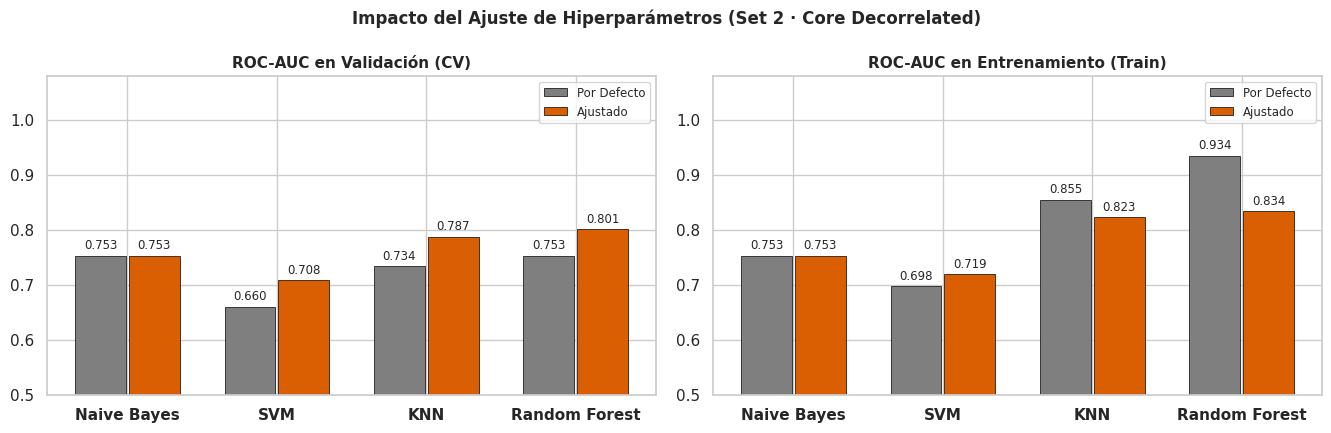

Figura guardada en: 'figures/16_comparacion_defecto_vs_ajustado.png'


Por Defecto                                    Ajustado  \
                  val_auc val_recall val_precision train_auc  val_auc   
modelo                                                                  
Naive Bayes         0.753      0.253         0.528     0.753    0.753   
SVM                 0.660      0.193         0.676     0.698    0.708   
KNN                 0.734      0.283         0.525     0.855    0.787   
Random Forest       0.753      0.305         0.515     0.934    0.801   

                                                       Δ             
              val_recall val_precision train_auc AUC Val Brecha Gap  
modelo                                                               
Naive Bayes        0.253         0.528     0.753   0.000      0.000  
SVM                0.105         0.705     0.719   0.048     -0.026  
KNN                0.201         0.661     0.823   0.053     -0.085  
Random Forest      0.233         0.633     0.834   0.048     -0.148

In [9]:
# 7.1 Síntesis y Comparación Numérica (Defecto vs. Ajustado)
ORDEN_MODELOS = ["Naive Bayes", "SVM", "KNN", "Random Forest"]

# Tabla resumen comparativa
res_def_mod = res_defecto.groupby("modelo")[["val_auc", "val_recall", "val_precision", "train_auc"]].mean().reindex(ORDEN_MODELOS)
res_aj_mod = res_ajustados.groupby("modelo")[["val_auc", "val_recall", "val_precision", "train_auc"]].mean().reindex(ORDEN_MODELOS)

comp_global = pd.concat({"Por Defecto": res_def_mod, "Ajustado": res_aj_mod}, axis=1)
comp_global[("Δ", "AUC Val")] = comp_global[("Ajustado", "val_auc")] - comp_global[("Por Defecto", "val_auc")]
comp_global[("Δ", "Brecha Gap")] = (
    (comp_global[("Ajustado", "train_auc")] - comp_global[("Ajustado", "val_auc")]) -
    (comp_global[("Por Defecto", "train_auc")] - comp_global[("Por Defecto", "val_auc")])
)

# 7.2 Gráfico Comparativo: ROC-AUC en Validación y en Train
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
x_mod = np.arange(len(ORDEN_MODELOS))

for ax, met, tit in zip(axes, ["val_auc", "train_auc"], ["ROC-AUC en Validación (CV)", "ROC-AUC en Entrenamiento (Train)"]):
    for j, (cual, col, etq) in enumerate([("Por Defecto", C_GRIS, "Por Defecto"), ("Ajustado", C_NARANJA, "Ajustado")]):
        vals = comp_global[(cual, met)].values
        pos = x_mod - 0.18 + j * 0.36
        ax.bar(pos, vals, width=0.34, color=col, label=etq, edgecolor="black", linewidth=0.5)
        for xp, val in zip(pos, vals):
            ax.text(xp, val + 0.012, f"{val:.3f}", ha="center", fontsize=8.5)
    ax.set_xticks(x_mod)
    ax.set_xticklabels(ORDEN_MODELOS, fontweight="bold")
    ax.set_title(tit, fontsize=11, fontweight="bold")
    ax.set_ylim(0.5, 1.08)
    ax.legend(fontsize=8.5, loc="upper right")

fig.suptitle("Impacto del Ajuste de Hiperparámetros (Set 2 · Core Decorrelated)", fontsize=12, fontweight="bold")
plt.tight_layout()

fig.savefig("figures/16_comparacion_defecto_vs_ajustado.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura guardada en: 'figures/16_comparacion_defecto_vs_ajustado.png'")
comp_global.round(3)

## 8. Conclusiones Estratégicas y Selección del Candidato a Modelo Final

### 1. Síntesis de Hiperparámetros Óptimos Seleccionados:
| Clasificador | Hiperparámetros Seleccionados | Criterio de Elección | ROC-AUC (Defecto $\to$ Ajustado) | Brecha $\Delta$ (Train − Val) |
| :--- | :--- | :--- | :---: | :---: |
| **Random Forest** | `max_depth = 10`, `n_estimators = 50` | Máximo ROC-AUC con menor costo en meseta | $0.753 \to \mathbf{0.801}$ ($+0.048$) | Se reduce de $0.243 \to \mathbf{0.033}$ |
| **KNN** | $k = 101$, `weights = 'uniform'` | Saturación de densidad local en meseta | $0.734 \to \mathbf{0.787}$ ($+0.053$) | Se reduce de $0.190 \to \mathbf{0.036}$ |
| **Naive Bayes** | Configuración base (`GaussianNB`) | Sin ajuste adicional (benchmark generativo) | $0.753 \to 0.753$ | $0.000$ (alto sesgo) |
| **SVM** | Kernel RBF, $C = 0.01$ | Margen suave óptimo con menor sobreajuste | $0.660 \to \mathbf{0.708}$ ($+0.048$) | $\mathbf{0.011}$ (mínimo gap) |

---

### 2. Lecciones Teóricas Clave:
1. **El ajuste de hiperparámetros triunfa mitigando el sobreajuste:**  
   Las mejoras más contundentes (**Random Forest** $+0.048$ y **KNN** $+0.053$) provinieron de restringir la complejidad del modelo (árboles podados a profundidad 10 y vecindarios amplios con $k=101$). Esto desacopló a los clasificadores del ruido muestral y estabilizó sus fronteras.
2. **El dilema del umbral nominal (0.5):**  
   Al controlar el sobreajuste, las probabilidades estimadas por RF y KNN se vuelven menos extremas (más cercanas a la prevalencia real del $\approx 11\%$). En consecuencia, con el umbral rígido de $0.5$ el Recall nominal disminuye ($0.233$ en RF), pero **su capacidad de ordenamiento global (ROC-AUC) es dramáticamente superior** ($0.801$).

---

### 3. Selección del Candidato a Modelo Final: **Random Forest**
Fundamentamos formalmente la elección de **Random Forest** como el mejor clasificador para resolver el problema de Bank Marketing:
- **Máximo desempeño global:** Lidera el ranking con $\text{ROC-AUC} = \mathbf{0.801}$.
- **Excelente generalización:** Brecha mínima de sobreajuste ($0.033$).
- **Superioridad operativa frente a KNN:** Aunque KNN alcanza un respetable $0.787$, su predicción en producción requiere calcular distancias euclidianas contra los más de 24.000 clientes de entrenamiento, haciéndolo ineficiente para inferencia en tiempo real y opaco para la interpretación bancaria. Random Forest evalúa en microsegundos y permite auditar la importancia de las características.

---

### Próximos Pasos en el Paso 4 (Modelo Final y Evaluación en Test):
1. **Selección del umbral de corte óptimo:** Ajustar el umbral de decisión utilizando **exclusivamente las predicciones fuera de pliegue ($OOF$) de entrenamiento** mediante el criterio del punto ROC más cercano a $(0, 1)$ para maximizar el balance entre Recall y Precisión.
2. **Entrenamiento definitivo:** Reentrenar Random Forest (`max_depth=10`, `n_estimators=50`) sobre el 100% del conjunto de entrenamiento.
3. **Evaluación no sesgada en Test:** Evaluar **una única vez** sobre el conjunto de test independiente (`ds_test_set2_core_decorrelated.csv`) para certificar la generalización en producción.